# 02 — Effective Volume–Time, Rate Limits, and 8-Year Survey Timeline

**Feeds:** Paper I §4.1, §5.1, §5.2, Fig. 1, Fig. 3, Fig. 4, and Table 1. **Runs:** Suite 01 ($100 \times 10^6$ injections per model; Suite 08 matched-exposure ensembles plug into the same schema once `WP-5` runs on MSI).


In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/02/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/02")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"


knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
knsearch_results_latest.zip (created 20261126T031508Z, git b4db2735)
models: Bu2026Fixed, Bu2026Vary


## 1. Pooled $\langle VT\rangle$ and Poisson rate upper limits (Table 1)


In [2]:
display(lim[["n_runs", "n_simulated", "n_detected", "efficiency", "vt_gpc3_yr", "vt_err_empirical", "r90", "r95", "r95_err_mc", "r99"]])
NB.finding(f"Baseline $\mathcal{{R}}_{{95}} < {lim.loc[FIX, 'r95']:.0f}$ ($\iota = 25.8^\circ$) and $< {lim.loc[ISO, 'r95']:.0f}$ Gpc$^{{-3}}$ yr$^{{-1}}$ (isotropic) "
           f"for zero surviving candidates ($\varepsilon_{{\rm pipe}} = 1$). Pooled MC uncertainty on $\langle VT\rangle$ is "
           f"{100 * (lim.vt_err_empirical / lim.vt_gpc3_yr).max():.2f}% or smaller.")


,n_runs,n_simulated,n_detected,efficiency,vt_gpc3_yr,vt_err_empirical,r90,r95,r95_err_mc,r99
model,,,,,,,,,,
Bu2026Fixed,100,100000000,184316,0.001843,0.0156,3.57e-05,147.6,192,0.4394,295.2
Bu2026Vary,100,100000000,53948,0.0005395,0.004515,2.023e-05,510,663.6,2.973,1020


> **Result.** Baseline $\mathcal{R}_{95} < 192$ ($\iota = 25.8^\circ$) and $< 664$ Gpc$^{-3}$ yr$^{-1}$ (isotropic) for zero surviving candidates ($arepsilon_{m pipe} = 1$). Pooled MC uncertainty on $\langle VTangle$ is 0.45% or smaller.

## 2. Monthly sensitivity and cumulative 8-year limit evolution (Fig. 1)

Because simulated merger times are uniform across the survey, the $\langle VT\rangle$ accumulated in any epoch equals the pooled $\langle VT\rangle$ multiplied by the fraction of recovered injections exploding in that epoch.


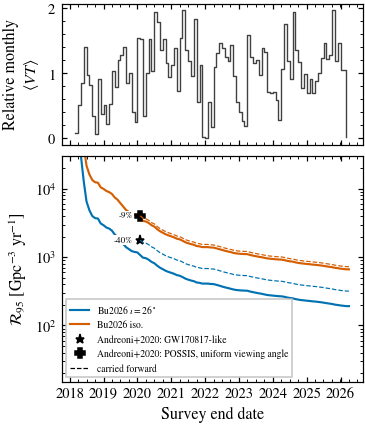

> **Result.** Monthly sensitivity spans 0.00× to 1.97× the survey mean (excluding partial boundary months); the two lowest-sensitivity full months are 2022-01, 2021-12.

In [3]:
SHOW_TIMELINE_LIT = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic"]
fig = F.sensitivity_timeline(ctx.tm, runs, M, SHOW_TIMELINE_LIT)
ctx.save(fig, "sensitivity_timeline"); plt.show()

e = A.vt_by_epoch(ctx.tm, runs, FIX); rel = e.vt_month / e.vt_month.mean()
low = e.loc[rel[1:-1].nsmallest(2).index, "month"].astype(str).tolist()
NB.finding(f"Monthly sensitivity spans {rel[1:-1].min():.2f}× to {rel.max():.2f}× the survey mean (excluding partial boundary months); "
           f"the two lowest-sensitivity full months are {', '.join(low)}.")


## 3. Direct comparison in Andreoni et al. (2020)'s 23-month window and ZTFReST carry-forward


,model,published,r95_window,window_change_vs_published,vt_gain_full_over_window,duration_gain,r95_full,published_projected_full,published_duration_scaled
0,Bu2026Fixed,1775,1069,-0.3976,5.568,4.177,192,318.8,425
1,Bu2026Vary,4029,3684,-0.08573,5.551,4.177,663.6,725.8,964.6


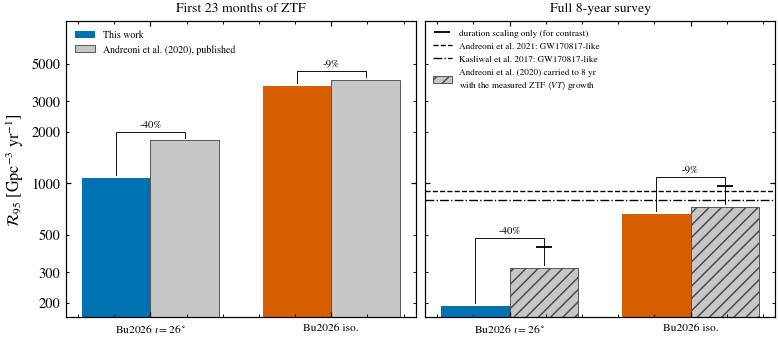

> **Result.** Restricted to Andreoni et al. (2020)'s 23-month Phase I window, our baseline limits are 40% (polar) and 9% (isotropic) tighter than published. Across all eight years, $\langle VTangle$ grows by 5.6× vs. 4.2× from survey duration alone.

> **Result.** Projecting 1775 Gpc$^{-3}$ yr$^{-1}$ forward with our measured $\langle VTangle(t)$ growth to 2021-03-03 predicts 907 Gpc$^{-3}$ yr$^{-1}$, closely matching ZTFReST's reported 900 Gpc$^{-3}$ yr$^{-1}$.

In [4]:
cmp = A.andreoni_comparison(ctx.tm, runs, M)
display(cmp[["model", "published", "r95_window", "window_change_vs_published", "vt_gain_full_over_window",
             "duration_gain", "r95_full", "published_projected_full", "published_duration_scaled"]])
fig = F.andreoni_window(cmp); ctx.save(fig, "andreoni_window"); plt.show()
c = cmp.set_index("model")
NB.finding(f"Restricted to Andreoni et al. (2020)'s 23-month Phase I window, our baseline limits are "
           f"{100 * -c.loc[FIX, 'window_change_vs_published']:.0f}% (polar) and {100 * -c.loc[ISO, 'window_change_vs_published']:.0f}% (isotropic) "
           f"tighter than published. Across all eight years, $\langle VT\rangle$ grows by {c.loc[FIX, 'vt_gain_full_over_window']:.1f}× "
           f"vs. {c.loc[FIX, 'duration_gain']:.1f}× from survey duration alone.")

a20, a21 = L.lookup("andreoni2020_gw170817"), L.lookup("andreoni2021_ztfrest_combined")
e_pos = e[e.vt_cumulative > 0]
upto = lambda d: e_pos[e_pos.month_end < pd.Timestamp(d) + pd.Timedelta(days=1)].iloc[-1].vt_cumulative
v20, v21 = upto(a20["data_end"]), upto(a21["data_end"])
NB.finding(f"Projecting 1775 Gpc$^{{-3}}$ yr$^{{-1}}$ forward with our measured $\langle VT\rangle(t)$ growth to {a21['data_end']} "
           f"predicts {a20['limit'] * v20 / v21:.0f} Gpc$^{{-3}}$ yr$^{{-1}}$, closely matching ZTFReST's reported {a21['limit']:g} Gpc$^{{-3}}$ yr$^{{-1}}$.")


## 4. Comparison with published optical limits and the GWTC-4.0 BNS merger rate (Fig. 3)


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)


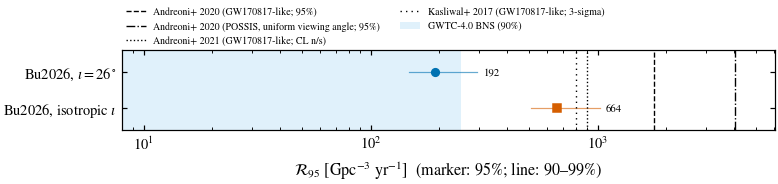

> **Result.** The polar AT2017gfo-like baseline limit enters the upper end of the GWTC-4.0 BNS merger band (7.6–250 Gpc$^{-3}$ yr$^{-1}$), whereas the isotropic baseline sits 2.7× above 250 Gpc$^{-3}$ yr$^{-1}$.

In [5]:
SHOW_LITERATURE = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic", "andreoni2021_ztfrest_combined",
                   "kasliwal2017_iptf", "gwtc4_bns_rate"]
fig = F.rate_limits(lim, M, SHOW_LITERATURE); ctx.save(fig, "rate_limits"); plt.show()
gw = L.lookup("gwtc4_bns_rate")
NB.finding(f"The polar AT2017gfo-like baseline limit enters the upper end of the GWTC-4.0 BNS merger band ({gw['low']:g}–{gw['high']:g} Gpc$^{{-3}}$ yr$^{{-1}}$), "
           f"whereas the isotropic baseline sits {lim.loc[ISO, 'r95'] / gw['high']:.1f}× above {gw['high']:g} Gpc$^{{-3}}$ yr$^{{-1}}$.")


## 5. Luminosity distance and redshift reach (Fig. 4)


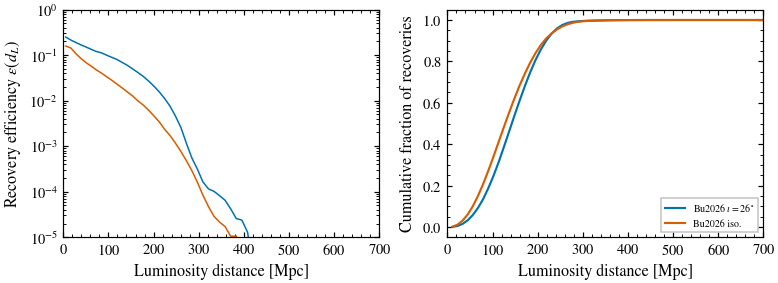

,dL50,dL90,dL99
Bu2026Fixed,143,219,275
Bu2026Vary,128,215,286


> **Result.** 50% of polar recoveries lie within 143 Mpc and 99% within 275 Mpc, well interior to the comoving injection boundary $z_{\max} = 0.15$.

In [6]:
fig = F.distance_reach(ctx.zh, runs, M); ctx.save(fig, "distance_reach"); plt.show()
q = pd.DataFrame({m: A.distance_quantiles(ctx.zh, m) for m in M}).T.round(0); display(q)
NB.finding(f"50% of polar recoveries lie within {q.loc[FIX, 'dL50']:.0f} Mpc and 99% within {q.loc[FIX, 'dL99']:.0f} Mpc, "
           f"well interior to the comoving injection boundary $z_{{\max}} = {runs.z_max.iloc[0]}$.")


## 6. Realisation-to-realisation binomial counting check


In [7]:
chk = []
for m in M:
    g = runs[runs.model == m]; p = g.n_detected.sum() / g.n_simulated.sum()
    chk.append(dict(model=m, observed_sd=g.n_detected.std(ddof=1), binomial_sd=np.sqrt(g.n_simulated.mean() * p * (1 - p))))
chk = pd.DataFrame(chk).set_index("model"); chk["ratio"] = chk.observed_sd / chk.binomial_sd; display(chk.round(2))
NB.finding(f"Observed scatter / binomial expectation = {chk.ratio.min():.2f}–{chk.ratio.max():.2f}: all 100 realisations behave as "
           "independent Poisson/binomial trials.")


,observed_sd,binomial_sd,ratio
model,,,
Bu2026Fixed,42.58,42.89,0.99
Bu2026Vary,24.63,23.22,1.06


> **Result.** Observed scatter / binomial expectation = 0.99–1.06: all 100 realisations behave as independent Poisson/binomial trials.